# 02 · Entrenamiento y evaluación de los modelos (Google Colab)

**Proyecto:** Emotion Detection Assistant · **Autor:** Edwar Trujillo · **Fase 2**

En este notebook:
1. Preparamos los datos: **limpieza de train** (ADR-006) y separación de un conjunto de **validación**.
2. Entrenamos el **modelo base**: réplica de la CNN del repositorio de referencia (atulapra/Emotion-detection).
3. Entrenamos el **modelo mejorado**: más capas, Batch Normalization, data augmentation, class weights,
   EarlyStopping y ReduceLROnPlateau.
4. Entrenamos el **modelo mejorado v2** (misma arquitectura, entrenamiento más largo) y probamos
   **test-time augmentation (TTA)**.
5. Evaluamos todo en el conjunto de **test** (que nunca se usó para entrenar), comparamos y elegimos el
   modelo final **usando validación**.

## Antes de empezar (en Colab)
1. **Entorno de ejecución → Cambiar tipo de entorno de ejecución → Acelerador de hardware: GPU (T4)** → Guardar.
2. En Google Drive debe existir `MyDrive/emotion-detection/archive.zip` (el zip de FER-2013 de Kaggle).
3. **Entorno de ejecución → Ejecutar todas** (o celda por celda con **Shift + Enter**).
4. La primera celda de Drive pide permiso para acceder a tu Google Drive: acepta con tu cuenta.

Los resultados (modelos, gráficas y métricas) se guardan en `MyDrive/emotion-detection/outputs/`,
así no se pierden si Colab se desconecta.

## 1. Configuración
Todas las constantes del experimento están aquí (**configuración centralizada**). Las más importantes:

- `BATCH_SIZE = 64`: cuántas imágenes ve el modelo antes de actualizar sus pesos una vez. Un *batch*
  más grande es más estable pero usa más memoria.
- `VALIDATION_FRACTION = 0.10`: el 10 % de train se aparta para **validación** (vigilar el entrenamiento
  sin tocar el test).
- Épocas: una **época** es una pasada completa por todas las imágenes de entrenamiento.

`FORCE_RETRAIN = False` significa: si un modelo ya está guardado en Drive, se carga en vez de reentrenarlo
(útil si Colab se desconecta a mitad del notebook).

In [1]:
import hashlib
import json
import os
import shutil
import sys
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers
from PIL import Image
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             top_k_accuracy_score)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# --- Reproducibilidad: misma semilla para Python, NumPy y TensorFlow ---
RANDOM_SEED = 42
keras.utils.set_random_seed(RANDOM_SEED)
tf.get_logger().setLevel("ERROR")  # oculta avisos internos de TensorFlow que no son errores (p. ej. "retracing")

# --- Datos ---
CLASS_NAMES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_SIZE = 48                      # las imágenes de FER-2013 son de 48x48
INPUT_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 1)  # 1 canal = escala de grises
VALIDATION_FRACTION = 0.10
BATCH_SIZE = 64

# --- Modelo base (réplica del repositorio de referencia) ---
BASE_EPOCHS = 50
BASE_LEARNING_RATE = 1e-4

# --- Modelo mejorado ---
IMPROVED_MAX_EPOCHS = 100            # máximo: EarlyStopping lo detendrá antes
IMPROVED_LEARNING_RATE = 1e-3
EARLY_STOPPING_PATIENCE = 12
REDUCE_LR_PATIENCE = 4

# --- Modelo mejorado v2 (iteración 2: misma arquitectura, entrenamiento más largo) ---
V2_MAX_EPOCHS = 120
V2_EARLY_STOPPING_PATIENCE = 20
V2_REDUCE_LR_PATIENCE = 5

FORCE_RETRAIN = False

# --- Rutas: en Colab usamos Google Drive; fuera de Colab, las carpetas del repositorio ---
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/emotion-detection")
    ZIP_PATH = DRIVE_DIR / "archive.zip"
    DATA_DIR = Path("/content/fer2013")            # disco local de Colab: mucho más rápido que Drive
    OUTPUT_DIR = DRIVE_DIR / "outputs"
    MODELS_DIR = OUTPUT_DIR / "models"
    FIGURES_DIR = OUTPUT_DIR / "figures"
    METRICS_DIR = OUTPUT_DIR / "metrics"
else:
    PROJECT_ROOT = Path.cwd().parent
    ZIP_PATH = None
    DATA_DIR = PROJECT_ROOT / "data" / "fer2013"
    MODELS_DIR = PROJECT_ROOT / "models"
    FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
    METRICS_DIR = PROJECT_ROOT / "reports" / "metrics"

CHECKPOINTS_DIR = MODELS_DIR / "checkpoints"
for folder in (MODELS_DIR, FIGURES_DIR, METRICS_DIR, CHECKPOINTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
print("¿En Colab?:", IN_COLAB)
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponible:", gpus if gpus else "NINGUNA")
if not gpus:
    print("⚠️ Sin GPU el entrenamiento será MUY lento. En Colab: Entorno de ejecución → "
          "Cambiar tipo de entorno de ejecución → GPU T4.")

Mounted at /content/drive
¿En Colab?: True
TensorFlow: 2.21.0 | Keras: 3.13.2
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Descomprimir el dataset
Copiamos el zip desde Drive y lo descomprimimos en el disco local de Colab (`/content`).
Leer 35.887 archivos pequeños directamente desde Drive sería muy lento.

In [2]:
def find_dataset_root(base_dir: Path) -> Path:
    """Busca la carpeta que contiene train/ y test/ (el zip puede traer una subcarpeta extra)."""
    for candidate in [base_dir, *base_dir.rglob("*")]:
        if candidate.is_dir() and (candidate / "train").is_dir() and (candidate / "test").is_dir():
            return candidate
    raise FileNotFoundError(f"No encontré las carpetas train/ y test/ dentro de {base_dir}")


if IN_COLAB and not DATA_DIR.exists():
    if not ZIP_PATH.exists():
        raise FileNotFoundError(f"No existe {ZIP_PATH}. Sube archive.zip a MyDrive/emotion-detection/")
    print("Descomprimiendo... (puede tardar 1-2 minutos)")
    with zipfile.ZipFile(ZIP_PATH) as zip_file:
        zip_file.extractall(DATA_DIR)

DATA_DIR = find_dataset_root(DATA_DIR)
for split in ("train", "test"):
    for class_name in CLASS_NAMES:
        if not (DATA_DIR / split / class_name).is_dir():
            raise FileNotFoundError(f"Falta la carpeta {DATA_DIR / split / class_name}")
print("✅ Dataset listo en:", DATA_DIR)

Descomprimiendo... (puede tardar 1-2 minutos)
✅ Dataset listo en: /content/fer2013


## 3. Índice de imágenes y limpieza de train (ADR-006)
En el EDA (fase 1) encontramos **531 imágenes de test repetidas en train**: eso es **fuga de datos**, porque
el modelo "vería" durante el entrenamiento imágenes con las que luego se le evalúa, y la accuracy saldría inflada.

Limpieza (solo en **train**; el **test no se toca** para que el resultado sea comparable con otros trabajos):
1. Quitar de train las imágenes cuya huella MD5 aparece en test.
2. Quitar las imágenes idénticas que tienen etiquetas distintas (ruido: no sabemos cuál es la correcta).
3. Quitar los duplicados exactos que quedan dentro de train (dejamos una copia).

In [3]:
def file_md5(path: Path) -> str:
    """Huella MD5 del contenido del archivo: igual solo si los archivos son idénticos."""
    return hashlib.md5(path.read_bytes()).hexdigest()


records = []
for split in ("train", "test"):
    for label_index, class_name in enumerate(CLASS_NAMES):
        for file_path in sorted((DATA_DIR / split / class_name).iterdir()):
            if file_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                records.append({"split": split, "emotion": class_name, "label": label_index, "path": file_path})

images_df = pd.DataFrame(records)
images_df["md5"] = images_df["path"].map(file_md5)

train_raw = images_df[images_df["split"] == "train"].copy()
test_df = images_df[images_df["split"] == "test"].reset_index(drop=True)

# 1) Fuga: imágenes de train que también están en test
test_hashes = set(test_df["md5"])
leak_mask = train_raw["md5"].isin(test_hashes)
train_clean = train_raw[~leak_mask]

# 2) Etiquetas contradictorias: el mismo archivo con más de una emoción
labels_per_hash = train_clean.groupby("md5")["emotion"].nunique()
conflicting_hashes = set(labels_per_hash[labels_per_hash > 1].index)
conflict_mask = train_clean["md5"].isin(conflicting_hashes)
train_clean = train_clean[~conflict_mask]

# 3) Duplicados exactos restantes dentro de train (se conserva la primera copia)
duplicate_mask = train_clean["md5"].duplicated(keep="first")
train_clean = train_clean[~duplicate_mask].reset_index(drop=True)

cleaning_summary = {
    "train_before": int(len(train_raw)),
    "removed_leak_with_test": int(leak_mask.sum()),
    "removed_conflicting_labels": int(conflict_mask.sum()),
    "removed_exact_duplicates": int(duplicate_mask.sum()),
    "train_after": int(len(train_clean)),
    "test_unchanged": int(len(test_df)),
}
with open(METRICS_DIR / "cleaning_summary.json", "w", encoding="utf-8") as f:
    json.dump(cleaning_summary, f, indent=2)

for key, value in cleaning_summary.items():
    print(f"{key:30s} {value:,}")

per_class = pd.DataFrame({
    "train_before": train_raw["emotion"].value_counts(),
    "train_after": train_clean["emotion"].value_counts(),
}).reindex(CLASS_NAMES)
per_class["removed"] = per_class["train_before"] - per_class["train_after"]
per_class

train_before                   28,709
removed_leak_with_test         703
removed_conflicting_labels     73
removed_exact_duplicates       1,021
train_after                    26,912
test_unchanged                 7,178


,train_before,train_after,removed
emotion,,,
angry,3995,3776,219
disgust,436,350,86
fear,4097,3797,300
happy,7215,7030,185
neutral,4965,4822,143
sad,4830,4677,153
surprise,3171,2460,711


## 4. División train / validación y carga en memoria
Del train limpio apartamos un 10 % para **validación**, de forma **estratificada** (cada emoción conserva su
proporción). Así hay tres conjuntos con roles distintos:

| Conjunto | Para qué se usa |
|---|---|
| **Train** | El modelo aprende ajustando sus pesos con estas imágenes |
| **Validación** | Vigilar el entrenamiento en cada época (detectar sobreajuste, decidir cuándo parar) |
| **Test** | Solo al final, una vez, para medir el rendimiento real con imágenes nunca vistas |

Luego cargamos todas las imágenes en matrices de NumPy de forma `(n, 48, 48, 1)`. Son pequeñas, caben en memoria
y el entrenamiento es mucho más rápido que leer archivos en cada época.

In [4]:
train_df, val_df = train_test_split(
    train_clean, test_size=VALIDATION_FRACTION, stratify=train_clean["label"], random_state=RANDOM_SEED
)


def load_images(df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Lee las imágenes como matrices uint8 (0-255) de forma (n, 48, 48, 1) y sus etiquetas (0-6)."""
    images = np.stack([
        np.array(Image.open(p).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE)), dtype=np.uint8)
        for p in df["path"]
    ])
    return images[..., np.newaxis], df["label"].to_numpy(dtype=np.int32)


x_train, y_train = load_images(train_df)
x_val, y_val = load_images(val_df)
x_test, y_test = load_images(test_df)

print("Train:     ", x_train.shape)
print("Validación:", x_val.shape)
print("Test:      ", x_test.shape)
print("Rango de píxeles:", x_train.min(), "a", x_train.max(), "| tipo:", x_train.dtype)

Train:      (24220, 48, 48, 1)
Validación: (2692, 48, 48, 1)
Test:       (7178, 48, 48, 1)
Rango de píxeles: 0 a 255 | tipo: uint8


## 5. Pipeline de datos y *data augmentation*
`tf.data` entrega las imágenes al modelo en *batches* de forma eficiente: **mezcla** (*shuffle*) el orden en cada
época para que el modelo no aprenda el orden de los datos, y **precarga** (*prefetch*) el siguiente batch mientras
la GPU procesa el actual.

**Data augmentation** (solo para el modelo mejorado y solo en train): en cada época se aplican pequeñas
transformaciones aleatorias a las imágenes: volteo horizontal, rotación de hasta ±18°, zoom y desplazamiento
de hasta 10 %. Una cara feliz volteada sigue siendo una cara feliz, así que el modelo ve "imágenes nuevas" y
aprende rasgos que no dependen de la posición exacta. Esto **reduce el sobreajuste** (memorizar train en vez de
generalizar). Validación y test **nunca** se aumentan: se evalúa con las imágenes reales.

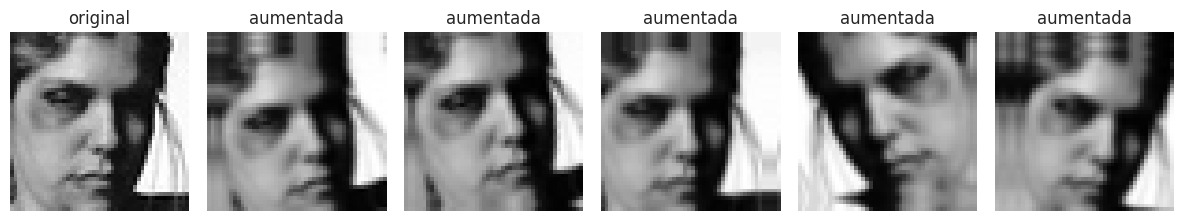

In [5]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),          # 0.05 de vuelta completa = ±18°
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.1, 0.1),
    ],
    name="data_augmentation",
)


def make_dataset(images: np.ndarray, labels: np.ndarray, training: bool, augment: bool = False) -> tf.data.Dataset:
    """Crea un tf.data.Dataset de batches; mezcla y aumenta solo cuando se pide."""
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        dataset = dataset.shuffle(len(images), seed=RANDOM_SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        dataset = dataset.map(lambda x, y: (data_augmentation(x, training=True), y),
                              num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.prefetch(tf.data.AUTOTUNE)


train_ds_plain = make_dataset(x_train, y_train, training=True)
train_ds_augmented = make_dataset(x_train, y_train, training=True, augment=True)
val_ds = make_dataset(x_val, y_val, training=False)
test_ds = make_dataset(x_test, y_test, training=False)

# Figura: una imagen original y 5 versiones aumentadas
sample = tf.cast(x_train[:1], tf.float32)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
axes[0].imshow(sample[0, ..., 0], cmap="gray")
axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(data_augmentation(sample, training=True)[0, ..., 0], cmap="gray")
    ax.set_title("aumentada")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "training_augmentation_examples.png", dpi=150)
plt.show()

## 6. Funciones comunes de entrenamiento y evaluación
Para no repetir código, definimos funciones que usan los dos modelos.

**Compilación** (`model.compile`) define cómo aprende el modelo:
- **Función de pérdida: entropía cruzada categórica** (*sparse categorical cross-entropy*). Mide qué tan lejos
  está la probabilidad que el modelo le da a la emoción correcta de 1. Si el modelo dice 0,9 para la correcta,
  la pérdida es baja; si dice 0,1, es alta. "Sparse" significa que las etiquetas son números (0-6) y no vectores.
- **Optimizador Adam**: ajusta los pesos en la dirección que reduce la pérdida (los gradientes se calculan con
  *backpropagation*). Adam adapta el tamaño del paso para cada peso, por eso converge rápido y es el estándar.
- **Métricas:** *accuracy* (top-1: acierta la emoción más probable) y *top-2 accuracy* (la correcta está entre
  las 2 más probables).

**Evaluación en test:** además de la accuracy, calculamos **precision** (de las veces que predijo X, cuántas eran X),
**recall** (de todas las X reales, cuántas encontró), **F1** (media armónica de las dos) por clase, y la
**matriz de confusión** (qué emociones confunde con cuáles).

In [6]:
def compile_model(model: keras.Model, learning_rate: float) -> keras.Model:
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=2, name="top2_accuracy")],
    )
    return model


def save_inference_model(model: keras.Model, build_fn, path: Path) -> None:
    """Guarda solo la arquitectura y los pesos, sin el estado del optimizador (archivo ~3 veces más liviano).
    Para eso construye una copia nueva del modelo (sin compilar) y le copia los pesos entrenados."""
    clean_model = build_fn()
    clean_model.set_weights(model.get_weights())
    clean_model.save(path)
    print(f"Modelo guardado: {path} ({path.stat().st_size / 1e6:.1f} MB)")


def train_or_load(name: str, build_fn, train_ds, epochs: int, learning_rate: float,
                  callbacks=None, class_weight=None):
    """Entrena el modelo y lo guarda; si ya existe en disco (y FORCE_RETRAIN es False), lo carga."""
    model_path = MODELS_DIR / f"{name}.keras"
    history_path = METRICS_DIR / f"{name}_history.csv"
    if model_path.exists() and history_path.exists() and not FORCE_RETRAIN:
        print(f"Cargando {name} ya entrenado desde {model_path}")
        model = compile_model(keras.models.load_model(model_path), learning_rate)
        info = json.loads((METRICS_DIR / f"{name}_training_info.json").read_text())
        return model, pd.read_csv(history_path), info

    model = compile_model(build_fn(), learning_rate)
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        callbacks=callbacks or [], class_weight=class_weight,
                        shuffle=False, verbose=2)  # shuffle=False: tf.data ya mezcla los datos
    info = {
        "training_minutes": round((time.time() - start) / 60, 2),
        "epochs_trained": len(history.history["loss"]),
        "parameters": int(model.count_params()),
        "tensorflow_version": tf.__version__,
        "keras_version": keras.__version__,
    }
    history_df = pd.DataFrame(history.history)
    history_df.index.name = "epoch"
    history_df.to_csv(history_path)
    (METRICS_DIR / f"{name}_training_info.json").write_text(json.dumps(info, indent=2))
    save_inference_model(model, build_fn, model_path)
    print(f"Entrenamiento: {info['epochs_trained']} épocas en {info['training_minutes']} minutos")
    return model, history_df, info


def plot_history(history_df: pd.DataFrame, name: str, title: str) -> None:
    """Curvas de pérdida y accuracy (train vs validación) por época."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = np.arange(1, len(history_df) + 1)
    axes[0].plot(epochs, history_df["loss"], label="train")
    axes[0].plot(epochs, history_df["val_loss"], label="validación")
    axes[0].set_title("Pérdida (cross-entropy)")
    axes[1].plot(epochs, history_df["accuracy"], label="train")
    axes[1].plot(epochs, history_df["val_accuracy"], label="validación")
    axes[1].set_title("Accuracy")
    for ax in axes:
        ax.set_xlabel("Época")
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}_learning_curves.png", dpi=150)
    plt.show()


def predict_probabilities(model: keras.Model, images: np.ndarray, use_tta: bool = False) -> np.ndarray:
    """Probabilidades por clase. Con TTA promedia la predicción de la imagen y la de su espejo horizontal."""
    images = images.astype("float32")
    probabilities = model.predict(images, batch_size=256, verbose=0)
    if use_tta:
        flipped = images[:, :, ::-1, :]  # invierte las columnas = espejo horizontal
        probabilities = (probabilities + model.predict(flipped, batch_size=256, verbose=0)) / 2
    return probabilities


def evaluate_on_test(model: keras.Model, name: str, title: str, use_tta: bool = False) -> dict:
    """Evalúa en test: accuracy top-1 y top-2, reporte por clase y matriz de confusión."""
    probabilities = predict_probabilities(model, x_test, use_tta)
    predictions = probabilities.argmax(axis=1)

    results = {
        "test_accuracy": round(float((predictions == y_test).mean()), 4),
        "test_top2_accuracy": round(float(top_k_accuracy_score(y_test, probabilities, k=2,
                                                               labels=range(NUM_CLASSES))), 4),
        "macro_f1": round(float(f1_score(y_test, predictions, average="macro")), 4),
        "weighted_f1": round(float(f1_score(y_test, predictions, average="weighted")), 4),
    }

    report = classification_report(y_test, predictions, labels=range(NUM_CLASSES),
                                   target_names=CLASS_NAMES, digits=3, zero_division=0)
    report_df = pd.DataFrame(classification_report(y_test, predictions, labels=range(NUM_CLASSES),
                                                   target_names=CLASS_NAMES, output_dict=True,
                                                   zero_division=0)).T
    report_df.to_csv(METRICS_DIR / f"{name}_classification_report.csv")
    (METRICS_DIR / f"{name}_test_results.json").write_text(json.dumps(results, indent=2))

    # Matriz de confusión normalizada por fila: cada fila suma 1 (= recall de esa clase en la diagonal)
    matrix = confusion_matrix(y_test, predictions, labels=range(NUM_CLASSES), normalize="true")
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Emoción real")
    ax.set_title(f"Matriz de confusión normalizada: {title}")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}_confusion_matrix.png", dpi=150)
    plt.show()

    print(f"Accuracy (top-1): {results['test_accuracy']:.2%}")
    print(f"Top-2 accuracy:   {results['test_top2_accuracy']:.2%}")
    print(f"F1 macro:         {results['macro_f1']:.3f}\n")
    print(report)
    results["per_class_f1"] = {c: round(float(report_df.loc[c, "f1-score"]), 4) for c in CLASS_NAMES}
    return results

## 7. Modelo base: réplica de la CNN del repositorio de referencia
Una **red neuronal convolucional (CNN)** aprende filtros que detectan patrones en la imagen: las primeras capas
detectan bordes y texturas; las siguientes combinan eso en formas (ojos, cejas, boca) y las últimas deciden la emoción.

Capas de este modelo (igual que en atulapra/Emotion-detection):

| Capa | Qué hace |
|---|---|
| `Rescaling(1/255)` | **Normaliza** los píxeles de 0-255 a 0-1 dentro del modelo (así en tiempo real no hay que acordarse de hacerlo) |
| `Conv2D(32/64/128, 3x3, ReLU)` | Desliza filtros de 3x3 sobre la imagen y produce **mapas de características**. **ReLU** (max(0, x)) añade no linealidad para aprender patrones complejos |
| `MaxPooling2D(2x2)` | Se queda con el valor máximo de cada bloque de 2x2: reduce el tamaño a la mitad y hace la red más robusta a pequeños desplazamientos |
| `Dropout(0.25 / 0.5)` | En cada paso de entrenamiento "apaga" al azar ese porcentaje de neuronas para que la red no dependa de unas pocas: **reduce el sobreajuste** |
| `Flatten` | Convierte los mapas en un vector largo |
| `Dense(1024, ReLU)` | Capa totalmente conectada que combina todas las características |
| `Dense(7, softmax)` | Una salida por emoción; **softmax** las convierte en probabilidades que suman 1 |

Entrenamiento como en el repositorio: Adam con tasa de aprendizaje 0,0001, 50 épocas, batch de 64, sin data augmentation
ni class weights. Su accuracy publicada es **63,2 %**.

In [7]:
def build_base_model() -> keras.Model:
    return keras.Sequential(
        [
            keras.Input(shape=INPUT_SHAPE),
            layers.Rescaling(1.0 / 255),
            layers.Conv2D(32, (3, 3), activation="relu"),
            layers.Conv2D(64, (3, 3), activation="relu"),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.25),
            layers.Conv2D(128, (3, 3), activation="relu"),
            layers.MaxPooling2D((2, 2)),
            layers.Conv2D(128, (3, 3), activation="relu"),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.25),
            layers.Flatten(),
            layers.Dense(1024, activation="relu"),
            layers.Dropout(0.5),
            layers.Dense(NUM_CLASSES, activation="softmax"),
        ],
        name="base_model",
    )


build_base_model().summary()

Model: "base_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 44, 44, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         7,175 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,345,607 (8.95 MB)

 Trainable params: 2,345,607 (8.95 MB)

 Non-trainable params: 0 (0.00 B)

### 7.1 Entrenar el modelo base
Con GPU tarda unos minutos. En cada época verás `loss`, `accuracy`, `top2_accuracy` (train) y sus versiones `val_`
(validación). Fíjate en que la accuracy de train sigue subiendo mientras la de validación se estanca: eso es
**sobreajuste**, y es justo lo que el modelo mejorado intenta corregir.

Cargando base_model ya entrenado desde /content/drive/MyDrive/emotion-detection/outputs/models/base_model.keras


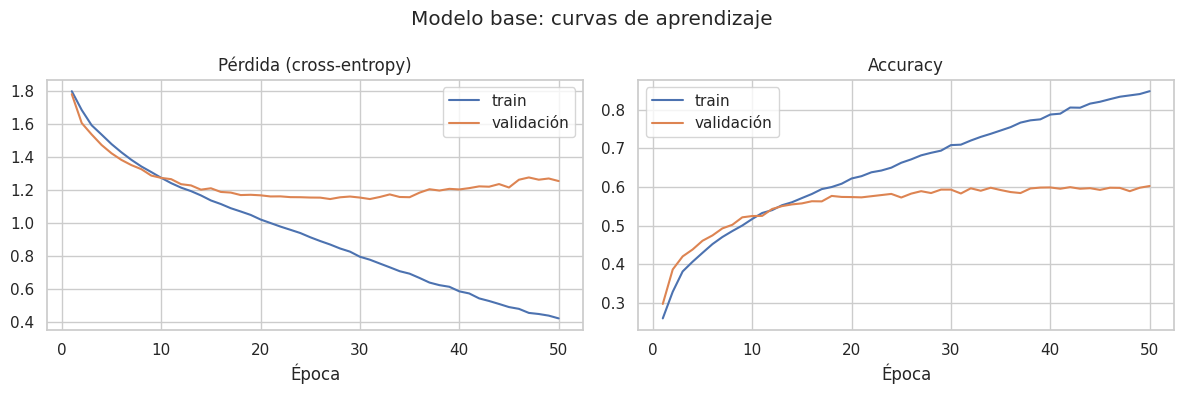

In [8]:
base_model, base_history, base_info = train_or_load(
    "base_model", build_base_model, train_ds_plain, epochs=BASE_EPOCHS, learning_rate=BASE_LEARNING_RATE
)
plot_history(base_history, "base_model", "Modelo base: curvas de aprendizaje")

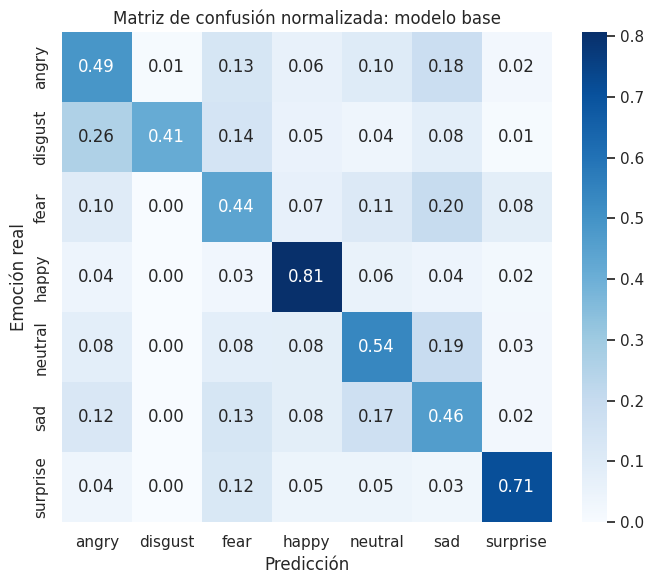

Accuracy (top-1): 58.87%
Top-2 accuracy:   77.38%
F1 macro:         0.568

              precision    recall  f1-score   support

       angry      0.489     0.489     0.489       958
     disgust      0.730     0.414     0.529       111
        fear      0.443     0.440     0.442      1024
       happy      0.790     0.806     0.798      1774
     neutral      0.537     0.536     0.537      1233
         sad      0.444     0.464     0.454      1247
    surprise      0.742     0.711     0.726       831

    accuracy                          0.589      7178
   macro avg      0.597     0.552     0.568      7178
weighted avg      0.590     0.589     0.589      7178



In [9]:
base_results = evaluate_on_test(base_model, "base_model", "modelo base")

## 8. Modelo mejorado
Cambios respecto al modelo base y su justificación:

| Mejora | Por qué |
|---|---|
| **Más capas en bloques** (64 → 128 → 256 → 512 filtros, dos convoluciones por bloque) | Más capacidad para aprender rasgos finos de la expresión. `padding="same"` conserva el tamaño en cada convolución |
| **Batch Normalization** después de cada convolución | Normaliza las activaciones de cada batch (media 0, varianza 1). Estabiliza y acelera el entrenamiento y permite una tasa de aprendizaje mayor (0,001) |
| **Data augmentation** | Más variedad de imágenes → menos sobreajuste (sección 5) |
| **Class weights** | Compensan el desbalance (disgust tiene ~16 veces menos imágenes que happy) |
| **EarlyStopping** | Detiene el entrenamiento cuando la pérdida de validación deja de mejorar durante 12 épocas y **recupera los mejores pesos** |
| **ReduceLROnPlateau** | Si la pérdida de validación se estanca 4 épocas, divide la tasa de aprendizaje entre 2: pasos más finos para afinar |
| **ModelCheckpoint** | Guarda en Drive el mejor modelo durante el entrenamiento (por si Colab se desconecta) |

### Class weights suavizados
La fórmula *balanced* da a "disgust" un peso de ~9. Con un peso tan alto el modelo empieza a predecir "disgust"
demasiado y la accuracy global baja. Por eso usamos la **raíz cuadrada** de esos pesos (~3 para disgust):
la clase minoritaria sigue recibiendo más atención, pero sin desequilibrar el resto. Es una práctica común
cuando el desbalance es fuerte.

In [10]:
balanced_weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
smoothed_weights = np.sqrt(balanced_weights)
class_weight = {i: float(w) for i, w in enumerate(smoothed_weights)}

pd.DataFrame({
    "emotion": CLASS_NAMES,
    "train_images": np.bincount(y_train, minlength=NUM_CLASSES),
    "balanced_weight": balanced_weights.round(3),
    "smoothed_weight_used": smoothed_weights.round(3),
}).to_csv(METRICS_DIR / "improved_model_class_weights.csv", index=False)
pd.read_csv(METRICS_DIR / "improved_model_class_weights.csv")

,emotion,train_images,balanced_weight,smoothed_weight_used
0,angry,3398,1.018,1.009
1,disgust,315,10.984,3.314
2,fear,3417,1.013,1.006
3,happy,6327,0.547,0.740
4,neutral,4340,0.797,0.893
5,sad,4209,0.822,0.907
6,surprise,2214,1.563,1.250


In [11]:
def conv_block(x, filters: int, dropout: float):
    """Dos convoluciones 3x3 con Batch Normalization y ReLU, seguidas de MaxPooling y Dropout."""
    for _ in range(2):
        x = layers.Conv2D(filters, (3, 3), padding="same", use_bias=False)(x)  # BN ya incluye el sesgo
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    return layers.Dropout(dropout)(x)


def build_improved_model() -> keras.Model:
    inputs = keras.Input(shape=INPUT_SHAPE)
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = conv_block(x, 64, 0.25)    # 48x48 -> 24x24
    x = conv_block(x, 128, 0.25)   # 24x24 -> 12x12
    x = conv_block(x, 256, 0.30)   # 12x12 -> 6x6
    x = conv_block(x, 512, 0.35)   # 6x6   -> 3x3
    x = layers.Flatten()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="improved_model")


build_improved_model().summary()

Model: "improved_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 48, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 48, 48, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 12, 12, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 5,872,455 (22.40 MB)

 Trainable params: 5,868,103 (22.39 MB)

 Non-trainable params: 4,352 (17.00 KB)

### 8.1 Entrenar el modelo mejorado


Cargando improved_model ya entrenado desde /content/drive/MyDrive/emotion-detection/outputs/models/improved_model.keras


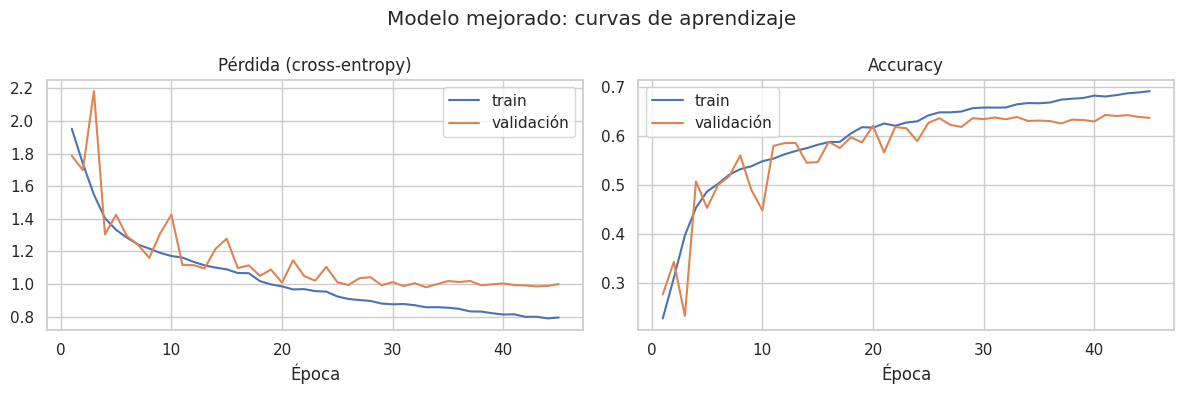

In [12]:
improved_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=EARLY_STOPPING_PATIENCE,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=REDUCE_LR_PATIENCE,
                                      min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(CHECKPOINTS_DIR / "improved_model_best.keras", monitor="val_loss",
                                    save_best_only=True),
]

improved_model, improved_history, improved_info = train_or_load(
    "improved_model", build_improved_model, train_ds_augmented, epochs=IMPROVED_MAX_EPOCHS,
    learning_rate=IMPROVED_LEARNING_RATE, callbacks=improved_callbacks, class_weight=class_weight,
)
plot_history(improved_history, "improved_model", "Modelo mejorado: curvas de aprendizaje")

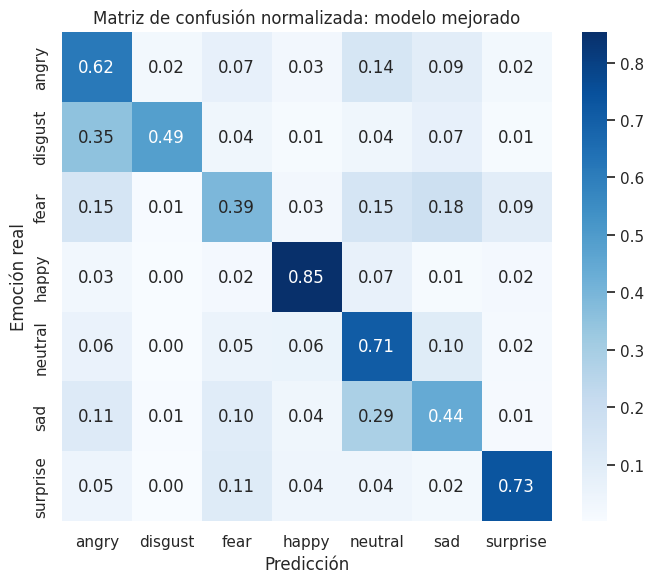

Accuracy (top-1): 64.00%
Top-2 accuracy:   82.28%
F1 macro:         0.605

              precision    recall  f1-score   support

       angry      0.543     0.617     0.578       958
     disgust      0.540     0.486     0.512       111
        fear      0.508     0.394     0.443      1024
       happy      0.880     0.853     0.867      1774
     neutral      0.521     0.708     0.600      1233
         sad      0.550     0.442     0.490      1247
    surprise      0.761     0.732     0.746       831

    accuracy                          0.640      7178
   macro avg      0.615     0.605     0.605      7178
weighted avg      0.644     0.640     0.637      7178



In [13]:
improved_results = evaluate_on_test(improved_model, "improved_model", "modelo mejorado")

## 9. Modelo mejorado v2 (segunda iteración)
El modelo mejorado (sección 8) se detuvo en la época 45 con 64 % de accuracy en test. Al revisar las curvas vimos
que EarlyStopping vigilaba la **pérdida** de validación: con data augmentation y class weights la pérdida puede
estancarse mientras la **accuracy** todavía mejora, así que el entrenamiento paró antes de tiempo.

Cambios de la v2 (**misma arquitectura**, solo cambia el entrenamiento, para aislar el efecto):

| Cambio | Por qué |
|---|---|
| EarlyStopping vigila `val_accuracy` con paciencia 20 | Se detiene según la métrica que nos importa y da más margen antes de parar |
| Máximo 120 épocas | Con data augmentation el modelo sigue mejorando despacio durante más épocas |
| ReduceLROnPlateau con paciencia 5 | Reduce la tasa de aprendizaje con algo más de calma |

### Test-time augmentation (TTA)
Al **evaluar**, el modelo predice cada imagen **dos veces**: la original y su espejo horizontal, y se promedian
las dos probabilidades. Es como pedir una segunda opinión: los errores de una predicción se compensan con la otra.
No requiere reentrenar. En tiempo real (fase 3) cuesta el doble de predicciones por rostro, que sigue siendo rápido.

Epoch 1/120
379/379 - 78s - 206ms/step - accuracy: 0.2223 - loss: 1.9515 - top2_accuracy: 0.4027 - val_accuracy: 0.2626 - val_loss: 1.8327 - val_top2_accuracy: 0.4421 - learning_rate: 0.0010
Epoch 2/120
379/379 - 19s - 50ms/step - accuracy: 0.2929 - loss: 1.7680 - top2_accuracy: 0.4877 - val_accuracy: 0.2875 - val_loss: 1.7517 - val_top2_accuracy: 0.4547 - learning_rate: 0.0010
Epoch 3/120
379/379 - 19s - 49ms/step - accuracy: 0.3802 - loss: 1.5909 - top2_accuracy: 0.5740 - val_accuracy: 0.2110 - val_loss: 2.0150 - val_top2_accuracy: 0.3767 - learning_rate: 0.0010
Epoch 4/120
379/379 - 19s - 51ms/step - accuracy: 0.4350 - loss: 1.4480 - top2_accuracy: 0.6382 - val_accuracy: 0.4309 - val_loss: 1.4660 - val_top2_accuracy: 0.6226 - learning_rate: 0.0010
Epoch 5/120
379/379 - 21s - 55ms/step - accuracy: 0.4711 - loss: 1.3643 - top2_accuracy: 0.6726 - val_accuracy: 0.4707 - val_loss: 1.4040 - val_top2_accuracy: 0.6679 - learning_rate: 0.0010
Epoch 6/120
379/379 - 20s - 52ms/step - accuracy:

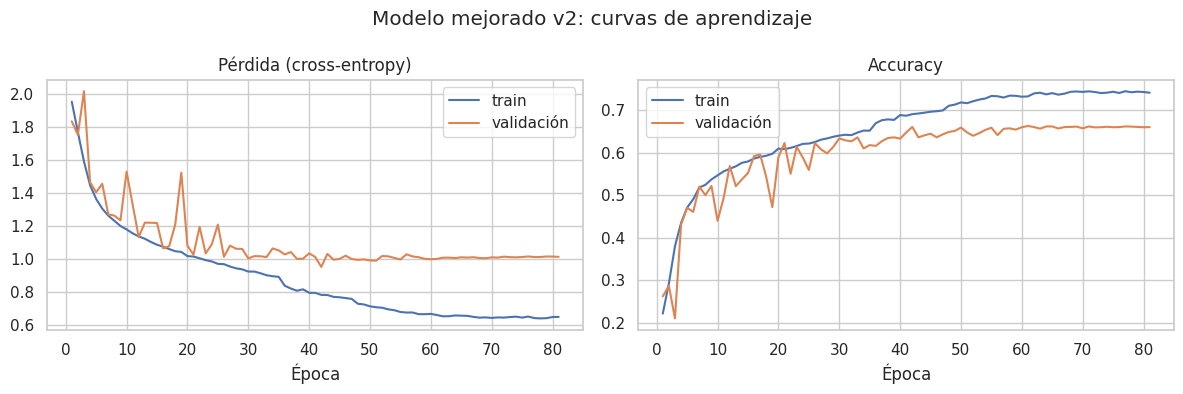

In [14]:
v2_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=V2_EARLY_STOPPING_PATIENCE,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=V2_REDUCE_LR_PATIENCE,
                                      min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(CHECKPOINTS_DIR / "improved_model_v2_best.keras", monitor="val_accuracy",
                                    mode="max", save_best_only=True),
]

improved_v2_model, improved_v2_history, improved_v2_info = train_or_load(
    "improved_model_v2", build_improved_model, train_ds_augmented, epochs=V2_MAX_EPOCHS,
    learning_rate=IMPROVED_LEARNING_RATE, callbacks=v2_callbacks, class_weight=class_weight,
)
plot_history(improved_v2_history, "improved_model_v2", "Modelo mejorado v2: curvas de aprendizaje")

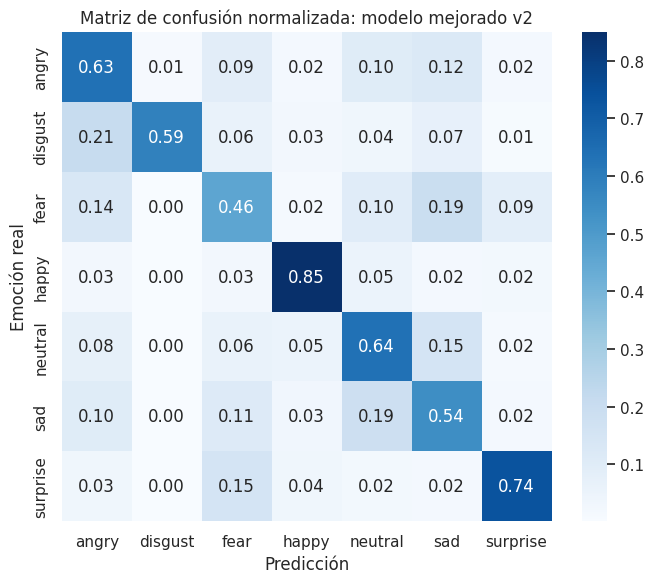

Accuracy (top-1): 65.90%
Top-2 accuracy:   83.37%
F1 macro:         0.643

              precision    recall  f1-score   support

       angry      0.568     0.635     0.600       958
     disgust      0.714     0.586     0.644       111
        fear      0.496     0.462     0.478      1024
       happy      0.896     0.850     0.872      1774
     neutral      0.589     0.637     0.612      1233
         sad      0.545     0.544     0.544      1247
    surprise      0.763     0.736     0.750       831

    accuracy                          0.659      7178
   macro avg      0.653     0.636     0.643      7178
weighted avg      0.663     0.659     0.660      7178



In [15]:
improved_v2_results = evaluate_on_test(improved_v2_model, "improved_model_v2", "modelo mejorado v2")

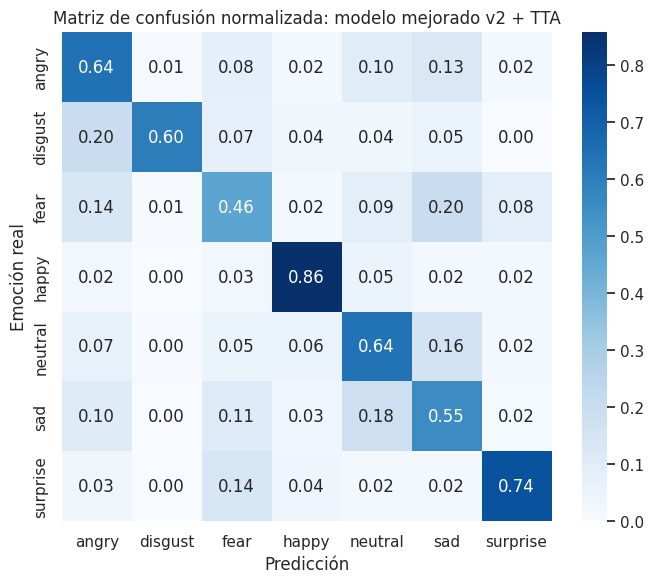

Accuracy (top-1): 66.54%
Top-2 accuracy:   83.63%
F1 macro:         0.650

              precision    recall  f1-score   support

       angry      0.580     0.641     0.609       958
     disgust      0.713     0.604     0.654       111
        fear      0.510     0.464     0.486      1024
       happy      0.892     0.857     0.874      1774
     neutral      0.597     0.639     0.618      1233
         sad      0.544     0.555     0.550      1247
    surprise      0.775     0.745     0.760       831

    accuracy                          0.665      7178
   macro avg      0.659     0.644     0.650      7178
weighted avg      0.669     0.665     0.666      7178



In [16]:
improved_v2_tta_results = evaluate_on_test(improved_v2_model, "improved_model_v2_tta",
                                           "modelo mejorado v2 + TTA", use_tta=True)

## 10. Comparación de los modelos
Tabla y gráficas con las métricas en **test**. El repositorio de referencia publicó 63,2 % de accuracy
(medido usando test como validación y sin quitar la fuga, por eso es optimista).

,base_model,improved_model,improved_model_v2,improved_model_v2_tta
test_accuracy,0.5887,0.64,0.659,0.6654
test_top2_accuracy,0.7738,0.8228,0.8337,0.8363
macro_f1,0.5678,0.6051,0.6429,0.6499
weighted_f1,0.5888,0.6371,0.6604,0.6663
training_minutes,5.14,15.65,27.54,27.54
epochs_trained,50,45,81,81
parameters,2345607,5872455,5872455,5872455
tensorflow_version,2.21.0,2.21.0,2.21.0,2.21.0
keras_version,3.13.2,3.13.2,3.13.2,3.13.2


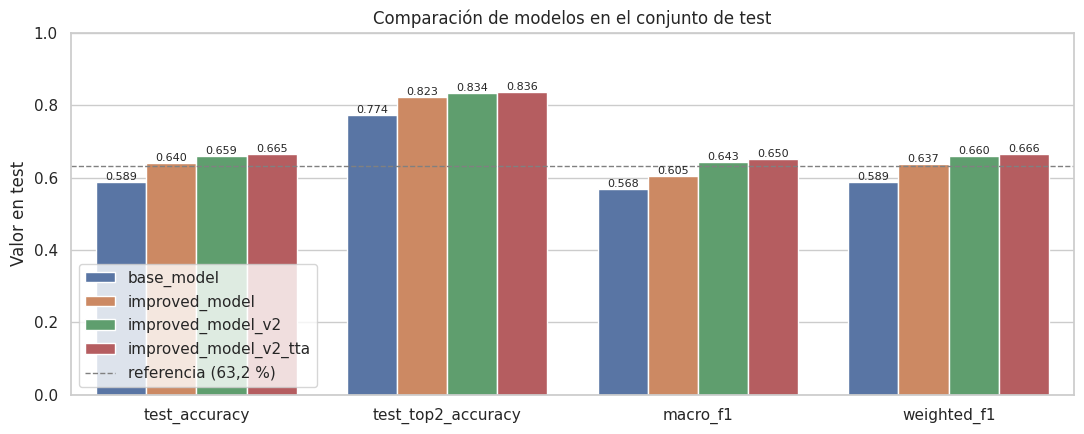

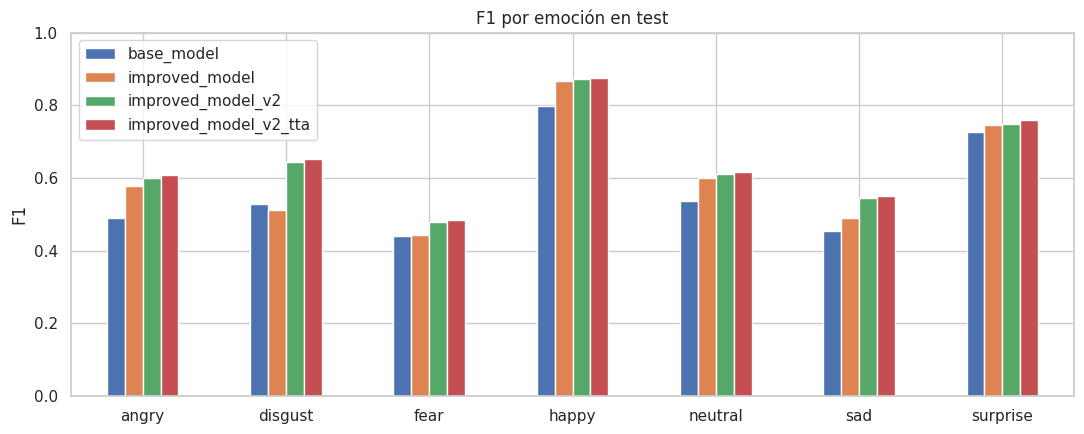

In [17]:
all_results = {
    "base_model": (base_results, base_info),
    "improved_model": (improved_results, improved_info),
    "improved_model_v2": (improved_v2_results, improved_v2_info),
    "improved_model_v2_tta": (improved_v2_tta_results, improved_v2_info),
}
comparison = pd.DataFrame({
    name: {**{k: v for k, v in results.items() if k != "per_class_f1"}, **info}
    for name, (results, info) in all_results.items()
})
comparison.to_csv(METRICS_DIR / "model_comparison.csv")
display(comparison)

# Métricas globales
metric_names = ["test_accuracy", "test_top2_accuracy", "macro_f1", "weighted_f1"]
plot_df = comparison.loc[metric_names].astype(float).reset_index().melt(
    id_vars="index", var_name="model", value_name="value")
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=plot_df, x="index", y="value", hue="model", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
ax.axhline(0.632, color="gray", linestyle="--", linewidth=1, label="referencia (63,2 %)")
ax.set_xlabel("")
ax.set_ylabel("Valor en test")
ax.set_ylim(0, 1)
ax.set_title("Comparación de modelos en el conjunto de test")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_comparison_metrics.png", dpi=150)
plt.show()

# F1 por clase
f1_df = pd.DataFrame({name: results["per_class_f1"]
                      for name, (results, _) in all_results.items()}).reindex(CLASS_NAMES)
f1_df.to_csv(METRICS_DIR / "model_comparison_f1_per_class.csv")
ax = f1_df.plot(kind="bar", figsize=(11, 4.5), rot=0)
ax.set_title("F1 por emoción en test")
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison_f1_per_class.png", dpi=150)
plt.show()

## 11. Selección del modelo final (con validación, no con test)
¿Cuál modelo usamos en la aplicación de tiempo real? Si eligiéramos el que mejor sale en **test**, estaríamos
usando el test para tomar una decisión, y su accuracy dejaría de ser una medida imparcial (otra forma de fuga).
Por eso elegimos con el conjunto de **validación**, y el test solo se usa para reportar.

In [18]:
candidates = {
    "improved_model": (improved_model, False),
    "improved_model_v2": (improved_v2_model, False),
    "improved_model_v2_tta": (improved_v2_model, True),
}
val_accuracy = {
    name: round(float((predict_probabilities(model, x_val, tta).argmax(axis=1) == y_val).mean()), 4)
    for name, (model, tta) in candidates.items()
}
selected_name = max(val_accuracy, key=val_accuracy.get)
selected_model, selected_tta = candidates[selected_name]
selection = {
    "selected": selected_name,
    "model_file": ("improved_model_v2" if "v2" in selected_name else "improved_model") + ".keras",
    "use_tta": selected_tta,
    "validation_accuracy": val_accuracy,
    "test_accuracy_of_selected": all_results[selected_name][0]["test_accuracy"],
}
(MODELS_DIR / "selected_model.json").write_text(json.dumps(selection, indent=2))
print(json.dumps(selection, indent=2))

{
  "selected": "improved_model_v2_tta",
  "model_file": "improved_model_v2.keras",
  "use_tta": true,
  "validation_accuracy": {
    "improved_model": 0.6389,
    "improved_model_v2": 0.6627,
    "improved_model_v2_tta": 0.6698
  },
  "test_accuracy_of_selected": 0.6654
}


## 12. Ejemplos de predicciones del modelo seleccionado
12 imágenes de test al azar con la emoción real, la predicha y su probabilidad (verde = acierto, rojo = error).
Útil para el video y para discutir los errores típicos.

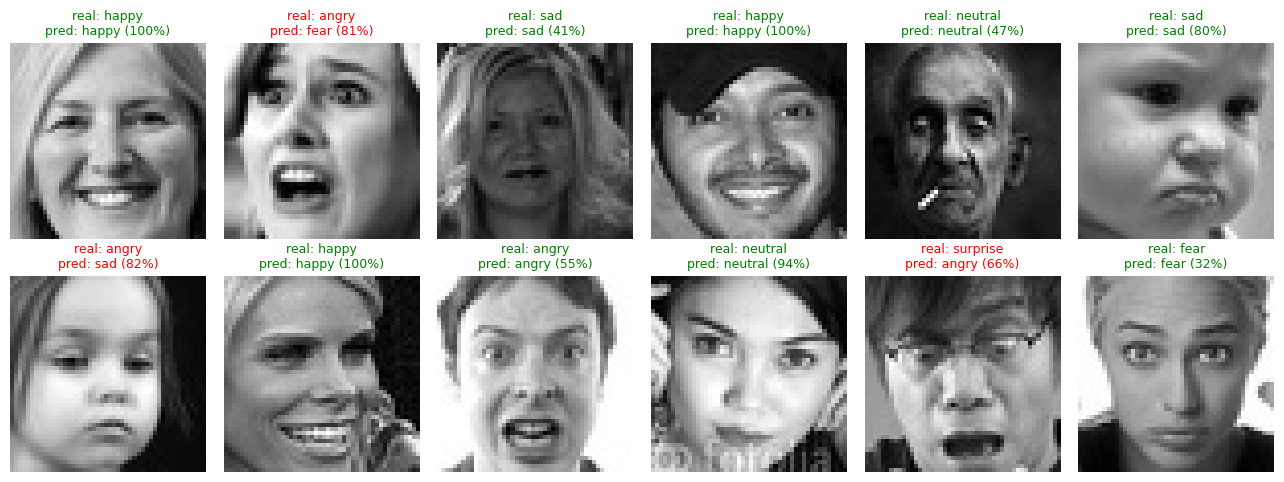

In [19]:
rng = np.random.default_rng(RANDOM_SEED)
sample_idx = rng.choice(len(x_test), size=12, replace=False)
sample_probs = predict_probabilities(selected_model, x_test[sample_idx], selected_tta)

fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, idx, probs in zip(axes.ravel(), sample_idx, sample_probs):
    predicted = probs.argmax()
    color = "green" if predicted == y_test[idx] else "red"
    ax.imshow(x_test[idx, ..., 0], cmap="gray")
    ax.set_title(f"real: {CLASS_NAMES[y_test[idx]]}\npred: {CLASS_NAMES[predicted]} ({probs[predicted]:.0%})",
                 fontsize=9, color=color)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "selected_model_sample_predictions.png", dpi=150)
plt.show()

## 13. Guardar etiquetas, verificar el modelo guardado y resumen
Guardamos el orden de las clases en `class_names.json`: la fase 3 lo necesita para traducir la salida del
modelo (un número del 0 al 6) a una emoción. Luego **recargamos** el modelo guardado y comprobamos que da las mismas
predicciones: así sabemos que el archivo `.keras` funciona antes de descargarlo.

In [20]:
(MODELS_DIR / "class_names.json").write_text(json.dumps(CLASS_NAMES, indent=2))

reloaded = keras.models.load_model(MODELS_DIR / selection["model_file"])
check_batch = x_test[:32].astype("float32")
same_predictions = np.array_equal(reloaded(check_batch, training=False).numpy().argmax(axis=1),
                                  selected_model(check_batch, training=False).numpy().argmax(axis=1))
print("✅ El modelo guardado da las mismas predicciones" if same_predictions
      else "⚠️ El modelo recargado da predicciones distintas: avisar")

final_summary = {
    "cleaning": cleaning_summary,
    "split_sizes": {"train": int(len(x_train)), "validation": int(len(x_val)), "test": int(len(x_test))},
    **{name: {**{k: v for k, v in results.items() if k != "per_class_f1"}, **info}
       for name, (results, info) in all_results.items()},
    "selection": selection,
    "reference_accuracy": 0.632,
}
(METRICS_DIR / "training_summary.json").write_text(json.dumps(final_summary, indent=2))
print(json.dumps(final_summary, indent=2))

print("\nArchivos generados:")
for folder in (MODELS_DIR, FIGURES_DIR, METRICS_DIR):
    for path in sorted(folder.glob("*.*")):
        print("  ", path.relative_to(folder.parent))

✅ El modelo guardado da las mismas predicciones
{
  "cleaning": {
    "train_before": 28709,
    "removed_leak_with_test": 703,
    "removed_conflicting_labels": 73,
    "removed_exact_duplicates": 1021,
    "train_after": 26912,
    "test_unchanged": 7178
  },
  "split_sizes": {
    "train": 24220,
    "validation": 2692,
    "test": 7178
  },
  "base_model": {
    "test_accuracy": 0.5887,
    "test_top2_accuracy": 0.7738,
    "macro_f1": 0.5678,
    "weighted_f1": 0.5888,
    "training_minutes": 5.14,
    "epochs_trained": 50,
    "parameters": 2345607,
    "tensorflow_version": "2.21.0",
    "keras_version": "3.13.2"
  },
  "improved_model": {
    "test_accuracy": 0.64,
    "test_top2_accuracy": 0.8228,
    "macro_f1": 0.6051,
    "weighted_f1": 0.6371,
    "training_minutes": 15.65,
    "epochs_trained": 45,
    "parameters": 5872455,
    "tensorflow_version": "2.21.0",
    "keras_version": "3.13.2"
  },
  "improved_model_v2": {
    "test_accuracy": 0.659,
    "test_top2_accuracy":